In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
import arviz as az

In [2]:
#Datele

In [3]:
n = 10
total = 180
print("Rata medie observata: ", total/n, "apeluri/ora")

Rata medie observata:  18.0 apeluri/ora


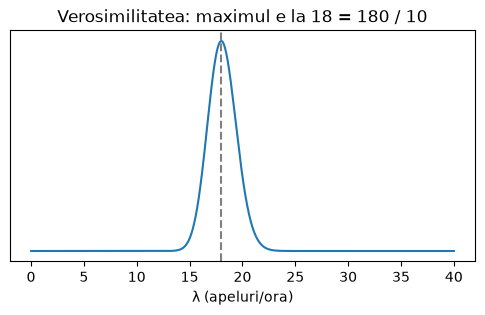

In [6]:
#Verosimilitatea

def verosimilitate(lam):
    return np.exp(total * np.log(lam) - n * lam - (total * np.log(total / n) - total))

lam = np.linspace(0.01, 40, 2000)
plt.figure(figsize=(6, 3))
plt.plot(lam, verosimilitate(lam))
plt.axvline(total / n, ls="--", color="gray")
plt.title("Verosimilitatea: maximul e la 18 = 180 / 10")
plt.xlabel("λ (apeluri/ora)"); plt.yticks([])
plt.show()

In [7]:
#Distributia a priori

In [8]:
alfa, beta = 2, 0.1

prior = stats.gamma(a=alfa, scale=1 / beta)
print(f"prior Gamma({alfa}, {beta}): media = {prior.mean():.1f}, abaterea std = {prior.std():.1f}, "
      f"moda = {(alfa - 1) / beta:.1f}")

prior Gamma(2, 0.1): media = 20.0, abaterea std = 14.1, moda = 10.0


In [9]:
#Distributia a posteriori

In [11]:
def posterior_gamma(alfa, beta, total, n):
    return alfa + total, beta + n

alfa_post, beta_post = posterior_gamma(alfa, beta, total, n)
posterior = stats.gamma(a=alfa_post, scale= 1 / beta_post)
print(f"posterior: Gamma({alfa_post}, {beta_post})")
print(f"media = {posterior.mean():.3f}, abaterea std = {posterior.std():.3f}")

posterior: Gamma(182, 10.1)
media = 18.020, abaterea std = 1.336


In [ ]:
#Un interval HDI al unei distributii

In [14]:
moda = (alfa_post - 1) / beta_post

def hdi_exact(dist, prob=0.94):
    lungime = lambda p: dist.ppf(p + prob) - dist.ppf(p)
    p = optimize.minimize_scalar(lungime, bounds=(0, 1 - prob), method="bounded").x
    return dist.ppf(p), dist.ppf(p + prob)

hdi_jos, hdi_sus = hdi_exact(posterior, 0.94)
print(f"moda (cea mai probabilă valoare) = {moda:.3f} apeluri/oră")
print(f"HDI 94% exact = [{hdi_jos:.3f}, {hdi_sus:.3f}]")
print(f"verificare: probabilitatea din interval = {posterior.cdf(hdi_sus) - posterior.cdf(hdi_jos):.4f}")

moda (cea mai probabilă valoare) = 17.921 apeluri/oră
HDI 94% exact = [15.530, 20.545]
verificare: probabilitatea din interval = 0.9400


In [ ]:
#Alegerea lui Alfa si Beta
